In [2]:
import numpy as np
import pandas as pd

In [3]:
df=pd.read_csv('advertising.csv')

In [4]:
df

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,14.0
197,177.0,9.3,6.4,14.8
198,283.6,42.0,66.2,25.5


In [5]:
x=df.iloc[:,0:3]
y=df.iloc[:,3]

In [6]:
from sklearn.model_selection import train_test_split

In [7]:
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=43)

In [8]:
from sklearn.linear_model import LinearRegression

In [9]:
lr=LinearRegression()

In [10]:
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.05,0.1 ,0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.503
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3


In [33]:
y_pred=lr.predict(X_test)
residual=y_test-y_pred

In [ ]:
#Assumptions:

In [11]:
#Linear Relationship between input and output columns

In [12]:
import matplotlib.pyplot as plt

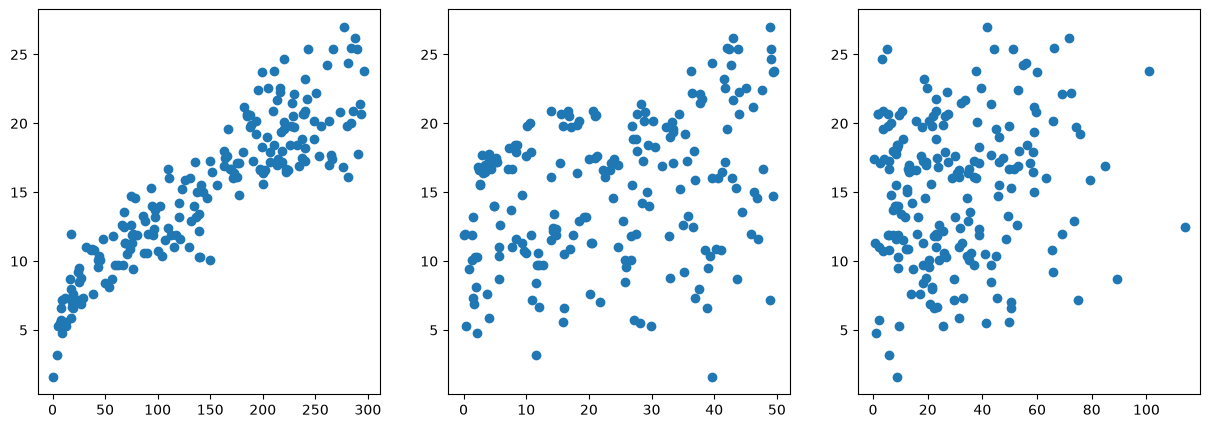

In [24]:
plt.figure(figsize=(15, 5))
plt.subplot(1,3,1)  #plt.subplot(rows,columns,position)
plt.scatter(df['TV'],df['Sales'])
plt.subplot(1,3,2) 
plt.scatter(df['Radio'],df['Sales'])
plt.subplot(1,3,3) 
plt.scatter(df['Newspaper'],df['Sales'])
plt.show()

In [25]:
#Multicolinearity

In [27]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif=[]
for i in range(X_train.shape[1]):
    vif.append(variance_inflation_factor(X_train,i))

In [28]:
vif

[np.float64(2.4432903955543064),
 np.float64(3.045155525397019),
 np.float64(2.8669369862911176)]

In [29]:
import seaborn as sns

<Axes: >

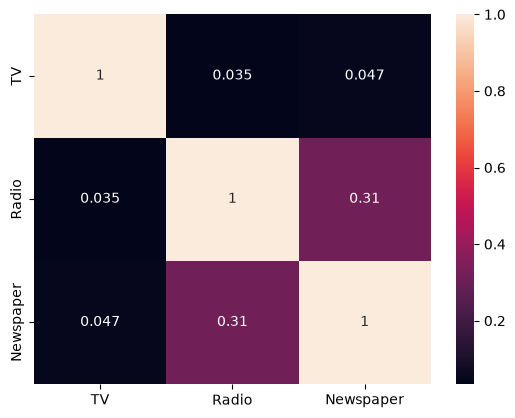

In [31]:
sns.heatmap(X_train.corr(),annot=True)

In [34]:
#Normality of Residual

In [35]:
residual

56    -2.501615
37     0.776232
67    -0.251228
79    -0.716219
80     0.251195
188   -0.656624
183    1.252096
10     3.797614
128    3.042838
62     1.432583
65     2.058604
17     0.205653
133   -0.558920
195    0.576348
146   -0.182126
38     0.318103
173    2.229984
149    0.378929
93    -0.068489
29     0.321178
0      0.839810
2      1.488792
122   -0.416503
180    2.161514
95    -0.010276
121   -0.990086
185    2.124871
39     0.502197
66     2.191955
19    -0.505974
11    -1.332672
45    -0.419522
41    -0.692992
92    -0.695883
168   -1.826951
1     -0.816795
57    -0.798993
189   -0.177865
151   -0.556665
167    0.812821
Name: Sales, dtype: float64

C:\Users\User\AppData\Local\Temp\ipykernel_10704\3308171749.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(residual,hist=False)


<Axes: xlabel='Sales', ylabel='Density'>

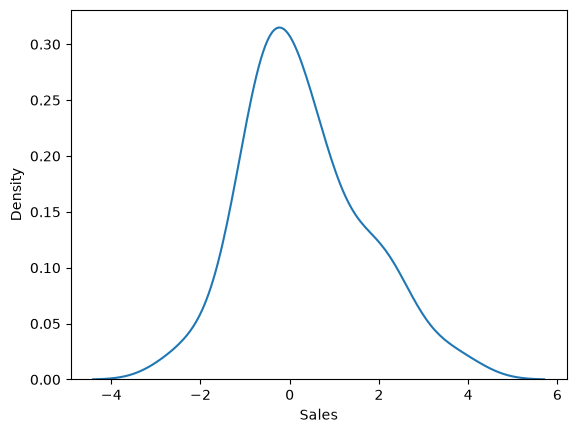

In [40]:
sns.distplot(residual,hist=False)

In [ ]:
#Homescedasticity

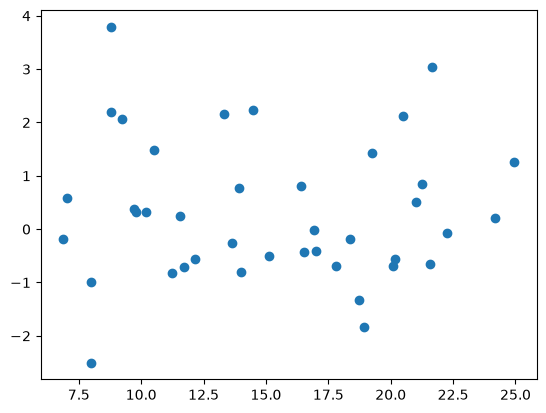

In [43]:
plt.scatter(y_pred,residual)

In [44]:
#No autocorrelation of error

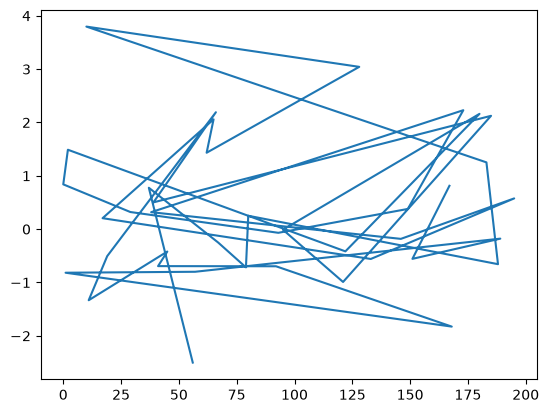

In [46]:
plt.plot(residual)